# Segmentación de clientes: de k-means "tal cual" a una segmentación defendible

**Perfil:** Riesgo de crédito (productos)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

¿Qué falla cuando se aplica k-means a variables en distintas escalas, con ruido y con grupos de forma elíptica? ¿Cómo se elige el número de segmentos con evidencia, y sirve una segmentación para predecir riesgo?

## Recorrido

1. Población sintética con 5 grupos latentes (se conoce la verdad), dos variables de puro ruido y escalas muy distintas.
2. **Versión 1:** k-means sobre las variables crudas.
3. **Diagnóstico:** qué variable domina la distancia y qué tan bien se recupera la verdad.
4. **Versión 2:** transformación, estandarización y selección de variables.
5. **Selección de k:** silueta, Calinski-Harabasz, Davies-Bouldin, *gap*, BIC y **estabilidad por bootstrap**.
6. **Versión 3:** mezcla gaussiana con covarianza completa.
7. Utilidad para riesgo, estabilidad en el tiempo, pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from scipy.stats import chi2_contingency, spearmanr
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import cross_val_predict

## 2. Población con cinco grupos latentes

Cada cliente pertenece a un grupo que el analista **no observa**. Los grupos difieren en ingreso, edad, uso del crédito, mora y antigüedad, con **correlación dentro del grupo** entre utilización y mora (clusters elípticos, no esféricos). Se añaden dos variables de **puro ruido**. El ingreso está en dólares (miles) y el resto en escalas pequeñas.

In [2]:
GRUPOS = [  # nombre, proporcion, ln(ingreso) (media, sd), edad (media, sd), utilizacion Beta(a, b), mora base, antiguedad, productos, PD
    ("estables",       0.30, (np.log(5200), 0.30), (48, 8),  (2, 8), 0.15, 9.0, 3.0, 0.02),
    ("jovenes",        0.20, (np.log(2600), 0.30), (27, 4),  (3, 6), 0.30, 2.0, 1.5, 0.04),
    ("revolventes",    0.22, (np.log(3000), 0.35), (40, 9),  (8, 3), 0.70, 5.0, 2.5, 0.07),
    ("alto_tensionado", 0.12, (np.log(9000), 0.35), (44, 8), (6, 3), 0.90, 6.0, 4.0, 0.09),
    ("morosos",        0.16, (np.log(1800), 0.35), (36, 10), (7, 2), 1.80, 3.0, 2.0, 0.22),
]
K_VERDAD = len(GRUPOS)


def generar(n, seed, deriva=0.0):
    rng = np.random.default_rng(seed)
    g = rng.choice(K_VERDAD, n, p=[x[1] for x in GRUPOS])
    ing, edad, util, mora, antig, prod, pdef = (np.empty(n) for _ in range(7))
    for k, (_, _, li, ed, ut, mo, an, pr, pd_) in enumerate(GRUPOS):
        m = g == k; nk = m.sum()
        ing[m] = np.exp(rng.normal(li[0] + deriva, li[1], nk))
        edad[m] = np.clip(rng.normal(*ed, nk), 18, 80)
        u = rng.beta(*ut, nk); util[m] = u
        mora[m] = np.clip(mo + 3.0 * (u - ut[0] / (ut[0] + ut[1])) + rng.normal(0, 0.25, nk), 0, None)   # correlacion con util
        antig[m] = rng.exponential(an, nk)
        prod[m] = rng.poisson(pr, nk)
        pdef[m] = pd_
    df = pd.DataFrame({"ingreso": ing, "edad": edad, "utilizacion": util, "mora_media": mora,
                       "antiguedad": antig, "n_productos": prod, "ruido1": rng.normal(0, 1, n), "ruido2": rng.normal(0, 1, n)})
    y = (rng.random(n) < pdef).astype(int)
    return df, g, y

X, g_ver, y = generar(6000, 2026)
print(X.shape, "| tasa de default global:", f"{y.mean():.3f}")
X.describe().loc[["mean", "std", "min", "max"]].T

(6000, 8) | tasa de default global: 0.081


,mean,std,min,max
ingreso,"4,344.9934","2,934.2769",432.7884,"35,363.3048"
edad,39.4504,10.8678,18.0000,76.8027
utilizacion,0.4975,0.2775,0.0019,0.9938
mora_media,0.7201,0.6687,0.0000,3.1037
antiguedad,5.3741,6.7708,0.0003,109.4716
n_productos,2.5075,1.7507,0.0000,12.0000
ruido1,-0.0001,1.0156,-3.9081,3.3825
ruido2,-0.0177,0.9980,-3.4756,3.8579


## 3. Versión 1: k-means sobre las variables crudas

k = 5 (el analista conoce el negocio), sin preprocesar. Se mide qué tanto recupera los grupos verdaderos con el **índice de Rand ajustado** (ARI: 1 = igual a la verdad, 0 = como al azar).

In [3]:
km1 = KMeans(n_clusters=K_VERDAD, n_init=10, random_state=0).fit(X.to_numpy())
ari1 = adjusted_rand_score(g_ver, km1.labels_)
sil1 = silhouette_score(X.to_numpy(), km1.labels_)
print(f"v1 (crudo):  ARI vs verdad = {ari1:.3f} | silueta = {sil1:.3f}")

v1 (crudo):  ARI vs verdad = 0.211 | silueta = 0.571


### 3.1 Diagnóstico: ¿qué variable manda?

In [4]:
var = X.var()
contrib = (var / var.sum()).rename("fraccion_de_la_varianza_total")
print("Fraccion de la varianza total que aporta cada variable (la distancia euclidea la hereda):")
contrib.to_frame().assign(pct=lambda t: t.iloc[:, 0] * 100).round(4)

Fraccion de la varianza total que aporta cada variable (la distancia euclidea la hereda):


,fraccion_de_la_varianza_total,pct
ingreso,1.0000,99.9980
edad,0.0000,0.0014
utilizacion,0.0000,0.0000
mora_media,0.0000,0.0000
antiguedad,0.0000,0.0005
n_productos,0.0000,0.0000
ruido1,0.0000,0.0000
ruido2,0.0000,0.0000


In [5]:
from sklearn.metrics import adjusted_rand_score as ari
sol_solo_ingreso = KMeans(5, n_init=10, random_state=0).fit_predict(X[["ingreso"]].to_numpy())
print(f"ARI de k-means usando SOLO el ingreso: {ari(g_ver, sol_solo_ingreso):.3f}")
print(f"ARI de k-means con las 8 variables crudas: {ari1:.3f}")
print(f"ARI entre ambas soluciones: {ari(sol_solo_ingreso, km1.labels_):.3f}  (1 = son la misma segmentacion)")
print()
print(f"Lectura: el ingreso aporta {contrib['ingreso']:.2%} de la varianza; la segmentacion con 8 variables es casi identica a la que usa solo ingreso.")

ARI de k-means usando SOLO el ingreso: 0.211
ARI de k-means con las 8 variables crudas: 0.211
ARI entre ambas soluciones: 0.999  (1 = son la misma segmentacion)

Lectura: el ingreso aporta 100.00% de la varianza; la segmentacion con 8 variables es casi identica a la que usa solo ingreso.


**Qué muestra.** K-means usa distancia euclidiana, así que las variables de mayor varianza dominan: aquí el ingreso (en dólares) borra al resto. No es un fallo del algoritmo sino de haberle dado variables sin poner en la misma escala.

## 4. Versión 2: transformar, estandarizar y quitar ruido

1. **Transformar**: el ingreso es log-normal; se usa su logaritmo. `n_productos` se deja, `mora_media` se deja.
2. **Estandarizar** todas las variables (media 0, varianza 1).
3. **Seleccionar variables**: se ajusta una primera solución y se calcula, por variable, la razón de varianza **entre** grupos sobre varianza **dentro** de los grupos (una F de ANOVA); se descartan las variables con razón baja (casi sin información para separar) y se vuelve a ajustar.

In [6]:
def preparar(df, columnas=None):
    d = df.copy()
    d["ingreso"] = np.log(d["ingreso"])
    return d if columnas is None else d[columnas]

def razon_F(Z, etiquetas):
    out = {}
    for j, c in enumerate(Z.columns):
        grupos = [Z[c].to_numpy()[etiquetas == k] for k in np.unique(etiquetas)]
        media = Z[c].mean()
        entre = sum(len(x) * (x.mean() - media) ** 2 for x in grupos) / (len(grupos) - 1)
        dentro = sum(((x - x.mean()) ** 2).sum() for x in grupos) / (len(Z) - len(grupos))
        out[c] = entre / dentro
    return pd.Series(out)

esc = StandardScaler()
Z_all = pd.DataFrame(esc.fit_transform(preparar(X)), columns=X.columns)
km_a = KMeans(5, n_init=10, random_state=0).fit(Z_all)
F_a = razon_F(Z_all, km_a.labels_)
print("Razon F por variable (entre/dentro) con la primera solucion estandarizada:")
F_a.sort_values(ascending=False).round(1).to_frame("F")

Razon F por variable (entre/dentro) con la primera solucion estandarizada:


,F
utilizacion,"3,557.8000"
mora_media,"2,827.2000"
antiguedad,"2,186.0000"
ingreso,"1,832.9000"
edad,"1,432.8000"
n_productos,595.6000
ruido1,3.8000
ruido2,3.5000


In [7]:
UMBRAL_F = 20
vars_sel = list(F_a[F_a > UMBRAL_F].index)
Z_sel = Z_all[vars_sel]
km2 = KMeans(5, n_init=10, random_state=0).fit(Z_sel)
ari2_todas = adjusted_rand_score(g_ver, km_a.labels_)
ari2 = adjusted_rand_score(g_ver, km2.labels_)
print(f"Variables retenidas (F > {UMBRAL_F}): {vars_sel}")
print(f"ARI v1 crudo = {ari1:.3f} | v2 estandarizado con las 8 variables = {ari2_todas:.3f} | v2 con seleccion de variables = {ari2:.3f}")

Variables retenidas (F > 20): ['ingreso', 'edad', 'utilizacion', 'mora_media', 'antiguedad', 'n_productos']
ARI v1 crudo = 0.211 | v2 estandarizado con las 8 variables = 0.471 | v2 con seleccion de variables = 0.471


Un aviso metodológico: seleccionar variables con una solución de clustering previa es **circular** (la variable "importa" porque ya separó los grupos que el algoritmo encontró). Aquí funciona porque las variables de ruido tienen F cercana a 1 y las informativas muy altas; con señales débiles esa regla es frágil.

## 5. ¿Cuántos segmentos? Seis criterios y una prueba de estabilidad

No existe un criterio universal. Se calculan seis y se comparan con la verdad conocida ($k=5$):

- **Silueta** (máx.), **Calinski-Harabasz** (máx.), **Davies-Bouldin** (mín.): internos y geométricos.
- **Gap statistic** (Tibshirani): compara la dispersión con la de datos uniformes.
- **BIC** de una mezcla gaussiana (mín.).
- **Estabilidad por bootstrap**: se ajusta k-means en dos remuestreos distintos, se asigna a todos los puntos con cada modelo y se mide el ARI entre ambas asignaciones. Una segmentación que cambia mucho al remuestrear no es de fiar.

In [8]:
def gap_stat(Z, ks, B=10, seed=0):
    rng = np.random.default_rng(seed)
    mins, maxs = Z.min(axis=0), Z.max(axis=0)
    gaps, sds = [], []
    for k in ks:
        W = np.log(KMeans(k, n_init=5, random_state=0).fit(Z).inertia_)
        ref = [np.log(KMeans(k, n_init=3, random_state=0).fit(rng.uniform(mins, maxs, Z.shape)).inertia_) for _ in range(B)]
        gaps.append(np.mean(ref) - W); sds.append(np.std(ref) * np.sqrt(1 + 1 / B))
    return np.array(gaps), np.array(sds)


def estabilidad(Z, k, B=10, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(B):
        i1, i2 = rng.integers(0, len(Z), len(Z)), rng.integers(0, len(Z), len(Z))
        m1 = KMeans(k, n_init=3, random_state=1).fit(Z[i1]); m2 = KMeans(k, n_init=3, random_state=2).fit(Z[i2])
        out.append(adjusted_rand_score(m1.predict(Z), m2.predict(Z)))
    return float(np.mean(out))


Zv = Z_sel.to_numpy()
ks = list(range(2, 9))
filas = []
for k in ks:
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(Zv)
    gm = GaussianMixture(k, covariance_type="full", n_init=3, random_state=0).fit(Zv)
    filas.append({"k": k, "silueta": silhouette_score(Zv, lab), "calinski_harabasz": calinski_harabasz_score(Zv, lab),
                  "davies_bouldin": davies_bouldin_score(Zv, lab), "BIC_gmm": gm.bic(Zv), "estabilidad_ARI": estabilidad(Zv, k)})
sel = pd.DataFrame(filas).set_index("k")
gaps, sds = gap_stat(Zv, ks)
sel["gap"] = gaps
sel.round(3)

,silueta,calinski_harabasz,davies_bouldin,BIC_gmm,estabilidad_ARI,gap
k,,,,,,
2,0.2530,"2,119.2940",1.5770,"85,743.1890",0.8630,1.4610
3,0.2290,"1,995.2280",1.3080,"82,744.0450",0.9580,1.4960
4,0.2430,"1,851.3770",1.4420,"80,450.8410",0.8580,1.5600
5,0.2510,"1,802.5200",1.3240,"71,197.6690",0.8950,1.6140
6,0.2400,"1,690.2880",1.4050,"71,131.1490",0.9290,1.6260
7,0.2260,"1,564.6130",1.4370,"70,520.1190",0.7840,1.6270
8,0.2040,"1,461.0140",1.4680,"69,979.1410",0.7610,1.6370


In [9]:
elegido = {
    "silueta (max)": int(sel["silueta"].idxmax()),
    "Calinski-Harabasz (max)": int(sel["calinski_harabasz"].idxmax()),
    "Davies-Bouldin (min)": int(sel["davies_bouldin"].idxmin()),
    "BIC gmm (min)": int(sel["BIC_gmm"].idxmin()),
}
# regla de Tibshirani: el menor k con gap(k) >= gap(k+1) - s(k+1)
regla = next((ks[i] for i in range(len(ks) - 1) if gaps[i] >= gaps[i + 1] - sds[i + 1]), ks[-1])
elegido["gap (Tibshirani)"] = int(regla)
# estabilidad: el mayor k cuya estabilidad sigue por encima de 0.8
est_ok = sel.index[sel["estabilidad_ARI"] >= 0.80]
elegido["estabilidad >= 0.80 (mayor k)"] = int(est_ok.max()) if len(est_ok) else None
pd.Series(elegido, name="k elegido").to_frame().assign(verdad=K_VERDAD)

,k elegido,verdad
silueta (max),2,5
Calinski-Harabasz (max),2,5
Davies-Bouldin (min),3,5
BIC gmm (min),8,5
gap (Tibshirani),6,5
estabilidad >= 0.80 (mayor k),6,5


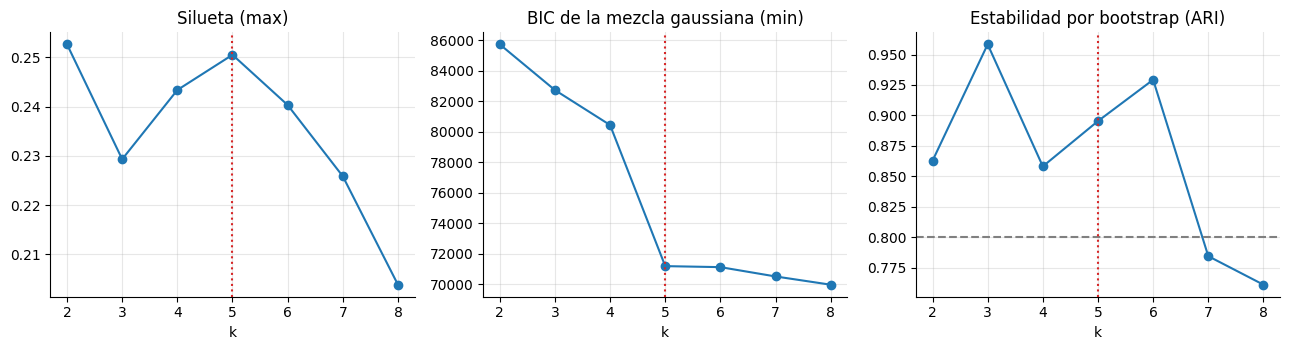

Lectura:
  Aviso: el BIC sigue bajando hasta el borde del rango (k=8); ese 'minimo' es el tope de la busqueda, no un minimo real. Habria que extender el rango.
  silueta (max)                    -> k = 2  (difiere de la verdad (5))
  Calinski-Harabasz (max)          -> k = 2  (difiere de la verdad (5))
  Davies-Bouldin (min)             -> k = 3  (difiere de la verdad (5))
  BIC gmm (min)                    -> k = 8  (difiere de la verdad (5))
  gap (Tibshirani)                 -> k = 6  (difiere de la verdad (5))
  estabilidad >= 0.80 (mayor k)    -> k = 6  (difiere de la verdad (5))


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(sel.index, sel["silueta"], "o-"); ax[0].set_title("Silueta (max)")
ax[1].plot(sel.index, sel["BIC_gmm"], "o-"); ax[1].set_title("BIC de la mezcla gaussiana (min)")
ax[2].plot(sel.index, sel["estabilidad_ARI"], "o-"); ax[2].axhline(0.8, ls="--", color="gray"); ax[2].set_title("Estabilidad por bootstrap (ARI)")
for a in ax: a.axvline(K_VERDAD, color="C3", ls=":"); a.set_xlabel("k")
plt.tight_layout(); plt.show()
print("Lectura:")
if elegido["BIC gmm (min)"] == max(ks):
    print(f"  Aviso: el BIC sigue bajando hasta el borde del rango (k={max(ks)}); ese 'minimo' es el tope de la busqueda, no un minimo real. Habria que extender el rango.")
for nombre, k in elegido.items():
    print(f"  {nombre:32s} -> k = {k}  ({'coincide con la verdad' if k == K_VERDAD else 'difiere de la verdad (' + str(K_VERDAD) + ')'})")

**Qué se aprende.** Los criterios **no coinciden entre sí** y varios pueden preferir un $k$ distinto de la verdad: cada uno mide algo distinto (compacidad, separación, verosimilitud, robustez). La decisión razonable combina evidencia estadística con **utilidad de negocio** (accionabilidad, tamaño mínimo de segmento) y exige que la solución sea estable.

## 6. Versión 3: mezcla gaussiana con covarianza completa

K-means asume clusters esféricos y de tamaño similar. Los grupos de esta población tienen **correlación interna** (utilización–mora), de modo que son elipses. Una mezcla gaussiana con covarianza completa *puede* modelarlos y entrega **probabilidades de pertenencia** en vez de asignaciones duras. Se prueba si en este caso mejora, y se compara contra un **techo supervisado**: lo mejor que se lograría si se conocieran las etiquetas verdaderas (QDA con validación cruzada). Ningún método no supervisado puede superar ese techo de forma sostenida.

In [11]:
gm3 = GaussianMixture(5, covariance_type="full", n_init=5, random_state=0).fit(Zv)
lab3 = gm3.predict(Zv)
gm3_diag = GaussianMixture(5, covariance_type="diag", n_init=5, random_state=0).fit(Zv)
pred_techo = cross_val_predict(QuadraticDiscriminantAnalysis(), Zv, g_ver, cv=5)
ari_techo = adjusted_rand_score(g_ver, pred_techo)
comp = pd.DataFrame({
    "ARI_vs_verdad": [ari1, ari2, adjusted_rand_score(g_ver, gm3_diag.predict(Zv)), adjusted_rand_score(g_ver, lab3), ari_techo],
    "silueta": [sil1, silhouette_score(Zv, km2.labels_), silhouette_score(Zv, gm3_diag.predict(Zv)), silhouette_score(Zv, lab3), np.nan],
    "BIC": [np.nan, np.nan, gm3_diag.bic(Zv), gm3.bic(Zv), np.nan],
}, index=["v1 k-means crudo", "v2 k-means estandarizado + seleccion", "v3a mezcla gaussiana (diagonal)", "v3b mezcla gaussiana (completa)", "techo supervisado (QDA con etiquetas)"])
comp.round(3)

,ARI_vs_verdad,silueta,BIC
v1 k-means crudo,0.2110,0.5710,NaN
v2 k-means estandarizado + seleccion,0.4710,0.2510,NaN
v3a mezcla gaussiana (diagonal),0.3920,0.1090,"74,259.0180"
v3b mezcla gaussiana (completa),0.4600,0.0980,"71,197.6690"
techo supervisado (QDA con etiquetas),0.8880,NaN,NaN


In [12]:
# ¿La brecha con el techo es un problema de optimizacion (optimo local) o de identificabilidad?
mu0 = np.array([Zv[g_ver == k].mean(axis=0) for k in range(K_VERDAD)])
w0 = np.bincount(g_ver, minlength=K_VERDAD) / len(g_ver)
prec0 = np.array([np.linalg.inv(np.cov(Zv[g_ver == k].T)) for k in range(K_VERDAD)])
gm_or = GaussianMixture(K_VERDAD, covariance_type="full", weights_init=w0, means_init=mu0, precisions_init=prec0, max_iter=300).fit(Zv)
ari_or = adjusted_rand_score(g_ver, gm_or.predict(Zv))
ll_or, ll_gm = gm_or.score(Zv), gm3.score(Zv)
print(f"Mezcla inicializada con los parametros verdaderos: ARI = {ari_or:.3f} | log-verosimilitud media = {ll_or:.4f}")
print(f"Mezcla con 5 inicios aleatorios (la de arriba):    ARI = {adjusted_rand_score(g_ver, lab3):.3f} | log-verosimilitud media = {ll_gm:.4f}")
if ll_or > ll_gm + 1e-3:
    print("Lectura: la inicializacion verdadera alcanza MAYOR verosimilitud: la mezcla de arriba quedo en un OPTIMO LOCAL. Mas inicios o una mejor inicializacion ayudarian.")
else:
    print("Lectura: la inicializacion verdadera NO supera la verosimilitud encontrada. No es un problema de optimizacion: el maximo de la verosimilitud gaussiana NO coincide con los grupos verdaderos (senal de especificacion erronea del modelo).")
prob = gm3.predict_proba(Zv)
incierto = (prob.max(axis=1) < 0.80).mean()
print(f"Lectura: ARI de la mezcla completa = {comp.loc['v3b mezcla gaussiana (completa)', 'ARI_vs_verdad']:.3f} | k-means v2 = {comp.loc['v2 k-means estandarizado + seleccion', 'ARI_vs_verdad']:.3f} | techo supervisado = {ari_techo:.3f}.")
print(f"  El techo supervisado es {'alto' if ari_techo > 0.8 else 'moderado'} ({ari_techo:.2f}): con etiquetas los grupos {'SI' if ari_techo > 0.8 else 'solo en parte'} son distinguibles.")
print(f"  v2 alcanza el {comp.loc['v2 k-means estandarizado + seleccion', 'ARI_vs_verdad'] / ari_techo:.0%} del techo; v1 (crudo), el {ari1 / ari_techo:.0%}. La brecha es el costo de no tener etiquetas.")
sil2 = comp.loc["v2 k-means estandarizado + seleccion", "silueta"]
print(f"  Cuidado con la silueta: v1 tiene {sil1:.2f} y v2 {sil2:.2f}, aunque v1 recupera mucho PEOR los grupos (ARI {ari1:.2f} vs {ari2:.2f}). La silueta no mide acuerdo con la verdad y premia estructuras dominadas por una sola dimension.")
print("  La mezcla completa mejora el BIC (modela bien la correlacion interna) pero no mejora la recuperacion de los grupos: ajustar mejor la densidad no es lo mismo que recuperar la verdad.")
print(f"El {incierto:.1%} de los clientes tiene probabilidad maxima de pertenencia < 80% (zonas de solapamiento): una asignacion dura los esconde.")
print("Mejora de BIC al pasar de covarianza diagonal a completa:", f"{gm3_diag.bic(Zv) - gm3.bic(Zv):,.0f}", "(positivo = mejor la completa)")

Mezcla inicializada con los parametros verdaderos: ARI = 0.875 | log-verosimilitud media = -6.5917
Mezcla con 5 inicios aleatorios (la de arriba):    ARI = 0.460 | log-verosimilitud media = -5.8324
Lectura: la inicializacion verdadera NO supera la verosimilitud encontrada. No es un problema de optimizacion: el maximo de la verosimilitud gaussiana NO coincide con los grupos verdaderos (senal de especificacion erronea del modelo).
Lectura: ARI de la mezcla completa = 0.460 | k-means v2 = 0.471 | techo supervisado = 0.888.
  El techo supervisado es alto (0.89): con etiquetas los grupos SI son distinguibles.
  v2 alcanza el 53% del techo; v1 (crudo), el 24%. La brecha es el costo de no tener etiquetas.
  Cuidado con la silueta: v1 tiene 0.57 y v2 0.25, aunque v1 recupera mucho PEOR los grupos (ARI 0.21 vs 0.47). La silueta no mide acuerdo con la verdad y premia estructuras dominadas por una sola dimension.
  La mezcla completa mejora el BIC (modela bien la correlacion interna) pero no mejo

### 6.1 Una hipótesis que se puede comprobar: ¿importa que las variables no sean gaussianas?

Las variables del generador son asimétricas o discretas (beta, gamma, exponencial, Poisson). Si la causa de la especificación errónea es esa, **acercarlas a la normalidad** debería mejorar la recuperación. Se prueba con transformaciones (logit para la utilización, raíz para mora y productos, log para la antigüedad) y se mide la asimetría antes y después.

In [13]:
from scipy.stats import skew

def preparar2(df):
    d = pd.DataFrame(index=df.index)
    u = np.clip(df["utilizacion"], 1e-3, 1 - 1e-3)
    d["ingreso"] = np.log(df["ingreso"]); d["edad"] = df["edad"]
    d["utilizacion"] = np.log(u / (1 - u))
    d["mora_media"] = np.sqrt(df["mora_media"]); d["antiguedad"] = np.log1p(df["antiguedad"]); d["n_productos"] = np.sqrt(df["n_productos"])
    return d

esc2 = StandardScaler()
Z2 = esc2.fit_transform(preparar2(X)[vars_sel])
asim_antes = np.abs(skew(Zv, axis=0)).mean(); asim_despues = np.abs(skew(Z2, axis=0)).mean()
km_t = KMeans(5, n_init=10, random_state=0).fit(Z2)
gm_t = GaussianMixture(5, covariance_type="full", n_init=5, random_state=0).fit(Z2)
ari_km_t, ari_gm_t = adjusted_rand_score(g_ver, km_t.labels_), adjusted_rand_score(g_ver, gm_t.predict(Z2))
print(f"Asimetria absoluta media de las variables: antes {asim_antes:.2f} | despues de transformar {asim_despues:.2f}")
print(f"ARI k-means:  {ari2:.3f} (solo log del ingreso) -> {ari_km_t:.3f} (transformaciones)")
print(f"ARI mezcla completa: {adjusted_rand_score(g_ver, lab3):.3f} -> {ari_gm_t:.3f}")
mejora = ari_gm_t - adjusted_rand_score(g_ver, lab3)
print("Lectura:", "las transformaciones MEJORAN la recuperacion: la no gaussianidad de las variables era parte del problema." if mejora > 0.05 else "las transformaciones NO mejoran de forma apreciable la recuperacion: la no gaussianidad marginal no explica la brecha con el techo.")

Asimetria absoluta media de las variables: antes 0.89 | despues de transformar 0.26
ARI k-means:  0.471 (solo log del ingreso) -> 0.426 (transformaciones)
ARI mezcla completa: 0.460 -> 0.494
Lectura: las transformaciones NO mejoran de forma apreciable la recuperacion: la no gaussianidad marginal no explica la brecha con el techo.


## 7. Utilidad para riesgo

Una segmentación vale en riesgo si **separa niveles de incumplimiento** y esa separación se mantiene en datos nuevos. Se mide:

1. Tasa de incumplimiento por segmento y prueba $\chi^2$ de independencia.
2. **Estabilidad fuera de muestra:** se asigna una población nueva (otra semilla) y se compara el ordenamiento de segmentos por incumplimiento.
3. Comparación honesta con un **modelo predictivo**: la tasa del segmento como predictor frente a una regresión logística sobre las mismas variables.

In [14]:
Xn, gn, yn = generar(6000, 777)
Zn = pd.DataFrame(esc.transform(preparar(Xn)), columns=X.columns)[vars_sel].to_numpy()
lab_n = gm3.predict(Zn)

tasa_tr = pd.Series(y).groupby(lab3).mean()
tasa_te = pd.Series(yn).groupby(lab_n).mean()
tab = pd.DataFrame({"clientes": pd.Series(lab3).value_counts().sort_index(), "tasa_train": tasa_tr, "tasa_test": tasa_te}).sort_values("tasa_train")
chi, p_chi, _, _ = chi2_contingency(pd.crosstab(lab3, y))
rho_ord = spearmanr(tab["tasa_train"], tab["tasa_test"])[0]
tab.round(4)

,clientes,tasa_train,tasa_test
3,1048,0.0239,0.0256
1,1135,0.0335,0.0322
0,899,0.0467,0.0591
4,1079,0.0964,0.0885
2,1839,0.1517,0.1335


In [15]:
auc_seg = roc_auc_score(yn, pd.Series(lab_n).map(tasa_tr).to_numpy())
lr = LogisticRegression(max_iter=2000).fit(StandardScaler().fit_transform(preparar(X)), y)
auc_lr = roc_auc_score(yn, lr.predict_proba(StandardScaler().fit(preparar(X)).transform(preparar(Xn)))[:, 1])
auc_techo = roc_auc_score(yn, pd.Series(gn).map({k: g[-1] for k, g in enumerate(GRUPOS)}).to_numpy())
print(f"chi2 de independencia segmento-default: p = {p_chi:.1e}")
print(f"Correlacion de rangos del ordenamiento de segmentos entre train y test: {rho_ord:+.2f}")
print(f"AUC en datos nuevos: tasa del segmento = {auc_seg:.3f} | regresion logistica = {auc_lr:.3f} | techo (usar el grupo verdadero) = {auc_techo:.3f}")

chi2 de independencia segmento-default: p = 1.3e-46
Correlacion de rangos del ordenamiento de segmentos entre train y test: +1.00
AUC en datos nuevos: tasa del segmento = 0.673 | regresion logistica = 0.698 | techo (usar el grupo verdadero) = 0.714


**Lectura.** La segmentación separa el riesgo y mantiene su orden fuera de muestra, pero **no sustituye a un modelo predictivo** si este está disponible con las mismas variables. Su valor es de **gestión** (políticas por grupo, interpretación), no de máxima discriminación.

## 8. Estabilidad en el tiempo: ¿qué conviene monitorear?

Si la población cambia, los segmentos cambian de tamaño. Se simulan poblaciones nuevas con distintos **desplazamientos del ingreso** (en logaritmos) y se comparan dos monitores:

- **PSI de composición:** cómo cambia el reparto de clientes entre segmentos.
- **PSI por variable:** cómo cambia la distribución de cada variable de entrada.

In [16]:
def psi(e, a, bins=10):
    e, a = np.asarray(e, float), np.asarray(a, float)
    cortes = np.unique(np.quantile(e, np.linspace(0, 1, bins + 1))); cortes[0], cortes[-1] = -np.inf, np.inf
    pe = np.clip(np.histogram(e, cortes)[0] / len(e), 1e-4, None); pa = np.clip(np.histogram(a, cortes)[0] / len(a), 1e-4, None)
    return float(((pa - pe) * np.log(pa / pe)).sum())

def psi_comp(p_e, p_a):
    p_e, p_a = np.clip(p_e, 1e-4, None), np.clip(p_a, 1e-4, None)
    return float(((p_a - p_e) * np.log(p_a / p_e)).sum())

p_ref = pd.Series(lab3).value_counts(normalize=True).sort_index()
filas = []
for deriva in (0.0, 0.12, 0.30, 0.60):
    Xd, _, _ = generar(6000, 888, deriva=deriva)
    Zd = pd.DataFrame(esc.transform(preparar(Xd)), columns=X.columns)[vars_sel].to_numpy()
    p_d = pd.Series(gm3.predict(Zd)).value_counts(normalize=True).reindex(p_ref.index).fillna(0)
    filas.append({"deriva_log_ingreso": deriva, "PSI_composicion": psi_comp(p_ref.to_numpy(), p_d.to_numpy()),
                  "PSI_ingreso": psi(X["ingreso"], Xd["ingreso"]), "PSI_edad": psi(X["edad"], Xd["edad"])})
monitor = pd.DataFrame(filas).set_index("deriva_log_ingreso")
monitor.round(4)

,PSI_composicion,PSI_ingreso,PSI_edad
deriva_log_ingreso,,,
0.0000,0.0021,0.0018,0.0011
0.1200,0.0023,0.0450,0.0011
0.3000,0.0107,0.2647,0.0011
0.6000,0.0626,1.0317,0.0011


In [17]:
print("Lectura:")
mod = monitor.loc[0.12]
ruido_i, ruido_c = monitor.loc[0.0, "PSI_ingreso"], monitor.loc[0.0, "PSI_composicion"]
print(f"  Deriva moderada (+12% en log del ingreso): PSI de composicion = {mod['PSI_composicion']:.4f} (ruido {ruido_c:.4f}, practicamente nada); PSI del ingreso = {mod['PSI_ingreso']:.3f} ({mod['PSI_ingreso'] / ruido_i:.0f} veces el ruido, aunque bajo el umbral convencional de 0.10).")
print(f"  Deriva fuerte (+60%): PSI de composicion = {monitor.loc[0.60, 'PSI_composicion']:.3f} -> {'cruza' if monitor.loc[0.60, 'PSI_composicion'] > 0.10 else 'NO cruza'} el umbral de 0.10; el PSI del ingreso ya es {monitor.loc[0.60, 'PSI_ingreso']:.2f}.")
print("  Con la composicion de segmentos como unico monitor, ni una deriva grande de una variable dispararia la alerta: conviene vigilar las variables de entrada.")

Lectura:
  Deriva moderada (+12% en log del ingreso): PSI de composicion = 0.0023 (ruido 0.0021, practicamente nada); PSI del ingreso = 0.045 (24 veces el ruido, aunque bajo el umbral convencional de 0.10).
  Deriva fuerte (+60%): PSI de composicion = 0.063 -> NO cruza el umbral de 0.10; el PSI del ingreso ya es 1.03.
  Con la composicion de segmentos como unico monitor, ni una deriva grande de una variable dispararia la alerta: conviene vigilar las variables de entrada.


## 9. Pruebas automáticas

In [18]:
# 9.1 el ARI se comporta bien en casos triviales
assert adjusted_rand_score([0, 0, 1, 1], [1, 1, 0, 0]) == 1.0           # invariante a renombrar etiquetas
assert abs(adjusted_rand_score(np.arange(100) % 2, np.random.default_rng(0).integers(0, 2, 100))) < 0.15
# 9.2 el ingreso crudo domina la varianza y la segmentacion cruda es casi la de solo ingreso
assert contrib["ingreso"] > 0.99
assert ari(sol_solo_ingreso, km1.labels_) > 0.9
# 9.3 preprocesar mejora la recuperacion de la verdad de forma sustancial
assert ari2 > 1.5 * ari1, f"preprocesar deberia mejorar sustancialmente la recuperacion ({ari2:.2f} vs {ari1:.2f})"
# 9.4 la seleccion de variables descarta el ruido y conserva las informativas
assert "ruido1" not in vars_sel and "ruido2" not in vars_sel
assert {"ingreso", "utilizacion", "mora_media"} <= set(vars_sel)
# 9.5 los criterios devuelven k validos; la estabilidad cae cuando k supera la verdad en exceso
assert all(2 <= k <= 8 for k in elegido.values() if k is not None)
assert sel["estabilidad_ARI"].loc[K_VERDAD] >= sel["estabilidad_ARI"].loc[8] - 0.05
# 9.6 la mezcla completa es al menos tan buena como la diagonal por BIC (hay correlacion interna)
assert gm3.bic(Zv) < gm3_diag.bic(Zv)
# 9.7 las probabilidades de pertenencia suman 1
assert np.allclose(prob.sum(axis=1), 1)
# 9.8 utilidad para riesgo: separa y es estable fuera de muestra, sin superar al techo
assert p_chi < 1e-6 and rho_ord > 0.8
assert auc_seg > 0.6 and auc_seg <= auc_techo + 0.01
# 9.9 el PSI por variable detecta la deriva moderada; el de composicion llega tarde
assert monitor.loc[0.12, "PSI_ingreso"] > 0.02 and monitor.loc[0.12, "PSI_ingreso"] > 10 * monitor.loc[0.0, "PSI_ingreso"]
assert monitor.loc[0.12, "PSI_composicion"] < monitor.loc[0.12, "PSI_ingreso"], "la composicion no deberia reaccionar mas que la variable"
assert monitor.loc[0.60, "PSI_composicion"] > monitor.loc[0.12, "PSI_composicion"], "con mas deriva la composicion debe reaccionar mas"
assert monitor["PSI_ingreso"].is_monotonic_increasing
# 9.9b la silueta cruda premia el resultado peor (metrica engañosa) y el techo supervisado es alto
assert sil1 > sil2 and ari1 < ari2, "la silueta de v1 deberia ser mayor aunque v1 recupere peor"
assert ari_techo > 0.8
assert monitor.loc[0.60, "PSI_composicion"] < 0.10 < monitor.loc[0.60, "PSI_ingreso"], "la composicion no cruza el umbral aun con deriva fuerte"
# 9.9c transformar a ~normalidad reduce la asimetria pero NO cierra la brecha con el techo (hipotesis descartada)
assert asim_despues < asim_antes / 2
assert (ari_gm_t - adjusted_rand_score(g_ver, lab3)) < 0.05 and (ari_techo - ari_gm_t) > 0.25
# 9.10 el techo supervisado no es superado por ningun metodo no supervisado (con holgura de ruido)
assert (comp["ARI_vs_verdad"].iloc[:4] <= ari_techo + 0.05).all()
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: k-means crudo | El ingreso (en dólares) concentra casi toda la varianza y la segmentación es casi la del ingreso solo | Nunca aplicar distancia euclidiana sin poner las variables en la misma escala |
| v2: transformar, estandarizar, seleccionar | Se recupera la estructura mucho mejor y se descartan las variables de ruido | Documentar la selección y su circularidad |
| Elección de k | Ninguno de los seis criterios acertó k = 5, y no coinciden entre sí; la estabilidad ayuda a descartar soluciones frágiles | Combinar estadística, estabilidad y utilidad de negocio |
| v3: mezcla gaussiana | Mejora el BIC al modelar la correlación interna, pero no la recuperación de los grupos; el techo supervisado (0,89) es mucho mayor que lo que logra cualquier método sin etiquetas | Usarla por las probabilidades de pertenencia; no confundir mejor densidad con mejor recuperación |
| Hipótesis descartada | Acercar las variables a la normalidad (asimetría 0,89 → 0,26) no cierra la brecha: ARI de la mezcla 0,46 → 0,49 frente a un techo de 0,89 | Dejar la causa como pregunta abierta en lugar de inventar una explicación |
| Métricas internas | La silueta de v1 (0,57) supera a la de v2 (0,25) aunque v1 recupera mucho peor | No elegir segmentaciones solo por silueta |
| Utilidad para riesgo | Separa el riesgo y es estable, pero no reemplaza a un modelo predictivo | Usar la segmentación para gestión, no para maximizar discriminación |
| Tiempo | El PSI de composición no cruza 0,10 ni con una deriva del 60 % del ingreso; el PSI por variable sí reacciona | Monitorear variables de entrada además del tamaño de los segmentos |

**Límites que no deben ocultarse**

- Los cinco grupos y su separación están diseñados; en datos reales la estructura es menos nítida y el ARI contra una verdad no existe.
- La selección de variables por razón F es circular y solo funciona bien con ruido claramente distinto de la señal.
- No hay una respuesta única para k: los criterios discrepan y la decisión final es parcialmente de negocio.
- No se identificó por qué la mezcla de máxima verosimilitud no recupera los grupos verdaderos: se descartaron el óptimo local (la inicialización verdadera tiene menor verosimilitud) y la no gaussianidad marginal.
- La comparación con la regresión logística usa un solo modelo y una sola población nueva.
- Datos sintéticos: los valores numéricos no son extrapolables.